# Week 2 · Activity recommendation
Yubo Xu

The experiment measures how features, sampling correction, learned ranking and diversity affect a synthetic activity feed. MovieLens‑1M provides a separate public benchmark. The train/test data are reproduced from the command line to keep the notebook usable without retraining on open.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

results = Path('reports/results')
fari = json.loads((results / 'w02_fari_retrieval.json').read_text())
ranking = json.loads((results / 'w02_fari_ranking.json').read_text())
pd.Series(fari['data'])

events                                                  31941
outcomes    {'start': 7486, 'completion': 15276, 'skip': 9...
users                                                    2000
items                                                     300
sparsity                                             0.949392
requests    {'train': 12555, 'validation': 1204, 'test': 1...
dtype: object

## Data and temporal split
Fari uses 2,000 simulated residents, 300 activity IDs and a 90-day horizon. Each log row stores an event outcome and a six-hour bucket. A completion is a positive interaction. History contains only earlier days in training and is frozen on day 75 for evaluation. Candidate recall uses days 76–82 for validation and 83–90 for testing. A random leave-one-out split can expose the model to interactions that happened after the request. Those future interactions can leak into user profiles, item popularity and co-occurrence patterns.

## Retrieval and features
- **User tower** uses resident ID, mean-pooled embeddings for up to 16 prior completions, and time of day.
- **Item tower** uses activity ID, category and a projected TF–IDF vector of the title. The normalized output supports dot-product search.
- **Training** uses in-batch negatives. The logQ variant estimates item inclusion probability using frequencies in the training set. Both versions use identical data, architecture and seed.
- **Metrics** report user-macro Recall@100, request-macro NDCG@10, and catalog coverage@100. Head is the most frequently completed 20% of catalog IDs in training. Head/tail recall weights individual targets.

In [2]:
metrics = ['recall@100', 'ndcg@10', 'coverage@100', 'head_recall@100', 'tail_recall@100']
pd.DataFrame(fari['test']).T[metrics].astype(float).round(4)

,recall@100,ndcg@10,coverage@100,head_recall@100,tail_recall@100
popularity,0.5661,0.0712,0.3333,1.0000,0.2688
time_decayed_popularity,0.5563,0.0689,0.3333,0.9873,0.2575
item_item_cf,0.5581,0.0609,1.0000,0.7880,0.3957
als,0.4548,0.0479,1.0000,0.5326,0.3982
ease_r,0.5292,0.0657,1.0000,0.7246,0.3945
two_tower,0.5233,0.0407,1.0000,0.6667,0.4296
two_tower_logq,0.5488,0.0544,1.0000,0.7554,0.4246
two_tower_logq_without_user_id,0.5651,0.0671,1.0000,0.8333,0.3894


In [3]:
display(pd.DataFrame(fari['test_recall_lift_vs_popularity']).T)
display(fari['user_id_ablation_recall_delta'])

,delta,ci95
two_tower,-0.042871,"[-0.07718511133266866, -0.005982053838484547]"
two_tower_logq,-0.017365,"[-0.04893652376204719, 0.01586905948820206]"


{'delta': 0.016367563974742438,
 'ci95': [-0.013542705217680293, 0.04752409438351612]}

In [4]:
movie = results / 'w02_movielens_retrieval.json'
if movie.exists():
    movie_results = json.loads(movie.read_text())
    display(pd.DataFrame(movie_results['test']).T[metrics].astype(float).round(4))

,recall@100,ndcg@10,coverage@100,head_recall@100,tail_recall@100
popularity,0.2383,0.0325,0.1107,0.3148,0.0000
time_decayed_popularity,0.2725,0.0313,0.1046,0.3259,0.0002
item_item_cf,0.1968,0.0314,0.1944,0.2792,0.0063
als,0.2274,0.0256,0.4600,0.2309,0.0430
ease_r,0.2180,0.0293,0.4424,0.2358,0.0317
two_tower,0.0739,0.0109,0.9990,0.0748,0.0490
two_tower_logq,0.1925,0.0254,0.4476,0.2581,0.0109


## Ranking and re-ranking
HNSW returns 200 activity IDs. LightGBM is trained using days 76–79. MMR selects an operating point with the highest diversity on days 80–82 among settings retaining at least 95% of the NDCG@10 at weight zero. NDCG measures relevance to historical completions. Category diversity is the fraction of distinct-position pairs with different categories. For each weight, the prior-24-hour rule is already applied. Scheduled reminders use a separate pinned input.

,ndcg@10,category_diversity
ANN order,0.054429,0.465919
LightGBM,0.054678,0.524092


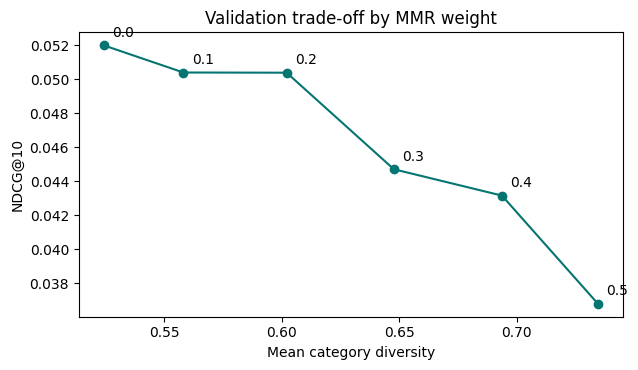

0.2

In [5]:
display(pd.DataFrame([ranking['test_retrieval_top10'], ranking['test_ranker_top10']],
                     index=['ANN order', 'LightGBM']))
curves = pd.DataFrame(ranking['mmr_validation']).T.astype(float)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(curves['category_diversity'], curves['ndcg@10'], 'o-', color='#057571')
for weight, row in curves.iterrows():
    ax.annotate(weight, (row['category_diversity'], row['ndcg@10']), xytext=(6, 6),
                textcoords='offset points')
ax.set(xlabel='Mean category diversity', ylabel='NDCG@10', title='Validation trade-off by MMR weight')
plt.tight_layout()
plt.show()
ranking['mmr_weight']

## Cold start and serving
Cold-start cohorts are defined by the number of observed training completions. These cohorts contain different residents. The proposed switch requires validation support for personalized ranking. When the candidate snapshot has no user vector or the ANN files fail to load, the API returns the global popularity list.

In [6]:
display(pd.DataFrame(ranking['cold_start_test']).T)
display(ranking['cold_start_switch_proposal'])
display(ranking['ann_exact_top200_overlap'])

,requests,ranker_ndcg@10,popularity_ndcg@10
0,4.0,0.000000,0.157732
1,11.0,0.032382,0.116989
3,95.0,0.021476,0.063893
5,186.0,0.058259,0.072080


None

1.0

## Reproduction

```sh
python -m pip install -e '.[recsys,dev]'
export OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1
python -m recsys.benchmark --user-id-ablation --output reports/results/w02_fari_retrieval.json
python -m recsys.benchmark --dataset movielens --movielens-zip /path/to/ml-1m.zip   --epochs 3 --output reports/results/w02_movielens_retrieval.json
python -m recsys.production --output runs/fari
cp runs/fari/ranking.json reports/results/w02_fari_ranking.json
```

MovieLens‑1M is available from [GroupLens](https://grouplens.org/datasets/movielens/1m/). Use the instructions in the candidate service README for the HTTP benchmark.